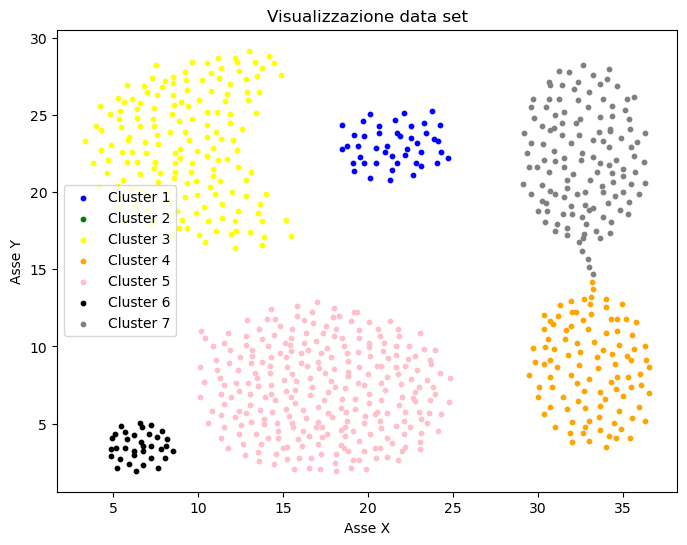

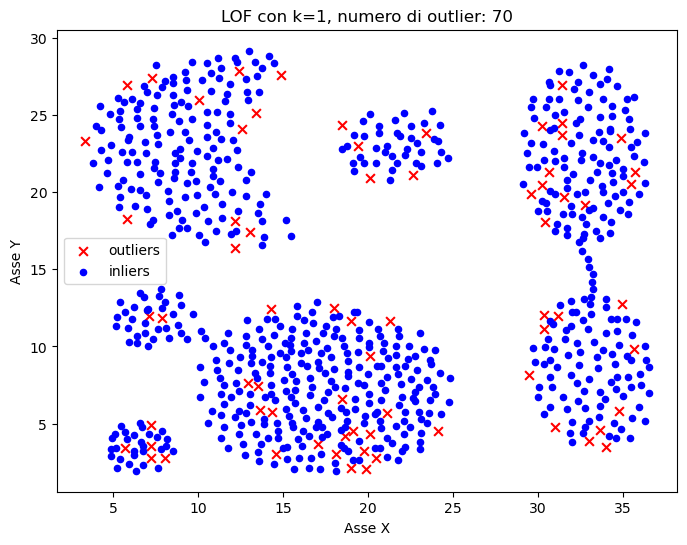

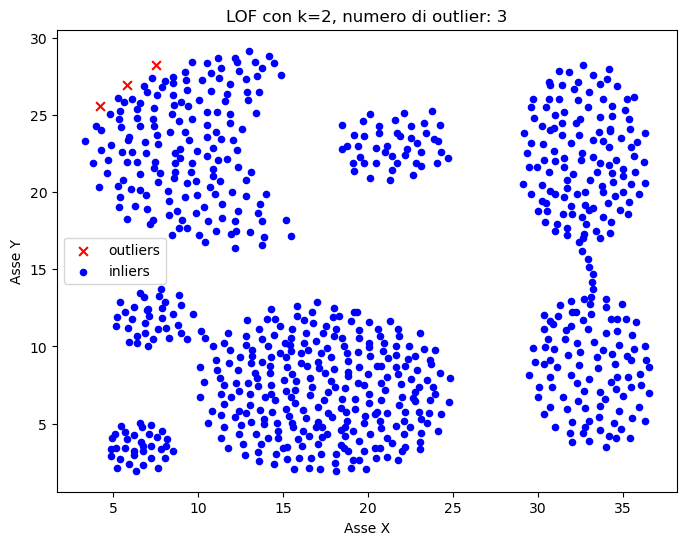

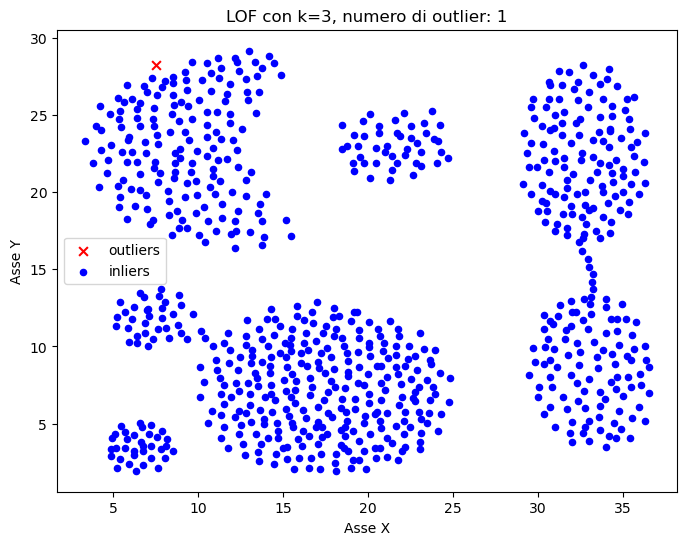

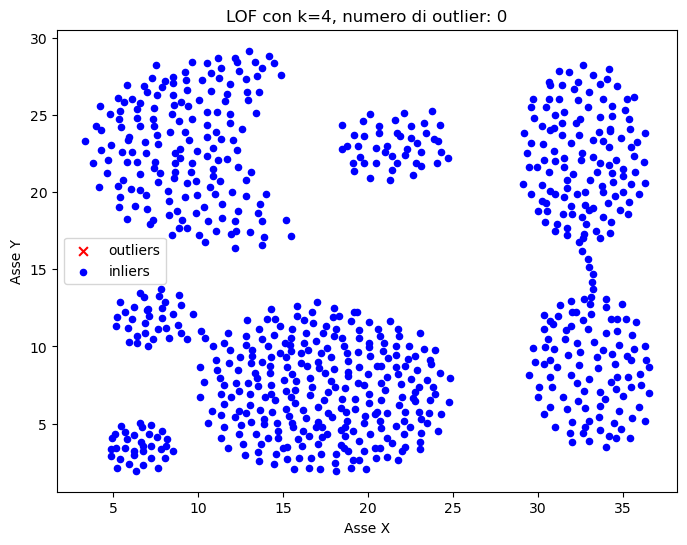

In [ ]:
# Local Outlier Factor
from sklearn.neighbors import LocalOutlierFactor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerPathCollection

# Caricamento dei dati e conversione in array NumPy
df = pd.read_csv("Aggregation.txt", sep="\t")
X = df.iloc[:, :2].values
y = df.iloc[:, 2].values

n_neighbors = [1,2,3,4]
model_lof = []
acc_list = []

# Visualizziamo il grafico
plt.figure(figsize=(8,6))

# scatter dei punti
plt.scatter(X[y==1, 0], X[y==1, 1], c='blue', label='Cluster 1', s=10)
plt.scatter(X[y==0, 0], X[y==0, 1], c='green', label='Cluster 2', s=10)
plt.scatter(X[y==2, 0], X[y==2, 1], c='yellow', label='Cluster 3', s=10)
plt.scatter(X[y==3, 0], X[y==3, 1], c='orange', label='Cluster 4', s=10)
plt.scatter(X[y==4, 0], X[y==4, 1], c='pink', label='Cluster 5', s=10)
plt.scatter(X[y==5, 0], X[y==5, 1], c='black', label='Cluster 6', s=10)
plt.scatter(X[y==6, 0], X[y==6, 1], c='grey', label='Cluster 7', s=10)


plt.title('Visualizzazione data set')
plt.xlabel('Asse X')
plt.ylabel('Asse Y')
plt.legend()

plt.show()
from sklearn.metrics import accuracy_score
for k in n_neighbors:
    lof = LocalOutlierFactor(n_neighbors=k)
    y_pred = lof.fit_predict(X)
    
    y_pred_binary = np.where(y_pred == -1,-1,1)
    y_binary = np.where(y == -1,-1,1)


    #contiamo quanti outlier ci sono 
    num_outlier = (y_pred == -1).sum()

    model_lof.append(lof)

    # Visualizzazioni risultati
    plt.figure(figsize=(8,6))
    # plot outlier  
    plt.scatter(X[y_pred_binary == -1, 0],X[y_pred_binary == -1, 1],color='red',label='outliers',
                marker='x', s=40)

    # plot inlier
    plt.scatter(X[y_pred_binary == 1, 0],X[y_pred_binary == 1, 1],color='blue',label='inliers',
                 s=20)

    plt.title(f"LOF con k={k}, numero di outlier: {num_outlier}")
    plt.xlabel("Asse X")
    plt.ylabel("Asse Y")
    plt.legend()
    
    plt.show()

In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix

def calcola_gini_medio(y_true, y_pred):
    # Escludiamo il rumore (-1) del DBSCAN
    valid_mask = (y_pred != -1)
    if valid_mask.sum() == 0:
        return 1.0  # Se tutto è rumore, restituiamo il massimo impuro/Gini alto
        
    y_t = y_true[valid_mask]
    y_p = y_pred[valid_mask]
    
    # Calcolo della matrice di confusione
    cm = confusion_matrix(y_t, y_p)
    
    # M_j è la dimensione totale di ciascun cluster j (somma sulle colonne)
    M_j = cm.sum(axis=0)
    
    g_j_list = []
    
    # Calcolo del Gini locale G_j per ciascun cluster j
    for j in range(cm.shape[1]):
        # CONTROLLO ANTI-DIVISIONE PER ZERO: procediamo solo se il cluster ha punti (M_j > 0)
        if M_j[j] > 0:
            sum_sq = np.sum((cm[:, j] / M_j[j]) ** 2)
            g_j = 1 - sum_sq
            g_j_list.append((g_j, M_j[j]))
            
    # Se per qualche motivo la lista è vuota
    if not g_j_list:
        return 1.0

    # Calcolo del Gini medio ponderato globale (G_average)
    numerator = sum(g * m for g, m in g_j_list)
    denominator = sum(m for _, m in g_j_list)
    
    if denominator == 0:
        return 1.0
        
    return numerator / denominator


In [22]:
# Clustering tramite DBSCAN
from sklearn.cluster import DBSCAN
import numpy as np

eps = [0.5, 1, 1.5]
min_samples = [2, 5, 7]

# Salviamo in queste variabili il miglior modello e il miglior indice di Gini
miglior_modello = None
miglior_gini = float('inf')  # Partiamo da infinito perché vogliamo MINIMIZZARE il Gini

for e in eps:
    for min_sample in min_samples:
        dbscan = DBSCAN(eps=e, min_samples=min_sample)
        cluster_pred = dbscan.fit_predict(X)

        # Calcoliamo il Gini medio con la routine
        gini = calcola_gini_medio(y, cluster_pred)
    
        # Vogliamo trovare il Gini PIÙ BASSO possibile
        if gini < miglior_gini:
            miglior_gini = gini
            miglior_modello = dbscan

# Stampiamo i risultati della ricerca
print(f'Miglior modello:\neps = {miglior_modello.eps}\nmin_samples = {miglior_modello.min_samples}')
print(f'Indice di Gini medio del miglior modello: {miglior_gini:5.4f}')


Miglior modello:
eps = 0.5
min_samples = 2
Indice di Gini medio del miglior modello: 0.0000


In [23]:
from sklearn.metrics import confusion_matrix
import numpy as np

for e in eps:
    for min_sample in min_samples:
        dbscan = DBSCAN(eps=e, min_samples=min_sample)
        cluster_pred = dbscan.fit_predict(X)
        
        # Stampiamo quanti cluster ha trovato (escludendo il rumore -1)
        unique_clusters = set(cluster_pred) - {-1}
        n_clusters_trovati = len(unique_clusters)
        n_rumore = (cluster_pred == -1).sum()
        
        print(f"Eps: {e}, Min_samples: {min_sample} --> Cluster trovati: {n_clusters_trovati}, Punti rumore (-1): {n_rumore}")
        
        # Calcoliamo il Gini se ci sono cluster validi
        if n_clusters_trovati > 0:
            valid_mask = (cluster_pred != -1)
            cm = confusion_matrix(y[valid_mask], cluster_pred[valid_mask])
            print("Matrice di confusione:")
            print(cm)
            print("-" * 40)


Eps: 0.5, Min_samples: 2 --> Cluster trovati: 126, Punti rumore (-1): 491
Matrice di confusione:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [2 2 4 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
----------------------------------------
Eps: 0.5, Min_samples: 5 --> Cluster trovati: 0, Punti rumore (-1): 787
Eps: 0.5, Min_samples: 7 --> Cluster trovati: 0, Punti rumore (-1): 787
Eps: 1, Min_samples: 2 --> Cluster trovati: 7, Punti rumore (-1): 5
Matrice di confusione:
[[  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0  44   0   0]
 [ 15 149   2   0   0   0   0   0]
 [  0   0   0   0 102   0   0   0]
 [  0   0   0 272   0   0   0   0]
 [  0   0   0   0   0   0  34   0]
 [  0   0   0   0 130   0   0   0]
 [  0   0   0  34   0   0   0   0]]
----------------------------------------
Eps: 1, Min_samples: 5 --> Cluster trovati: 13, Punti rumore (-1): 61
Matrice di confusione:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0

Eps: 0.5, Min_samples: 2 --> G_average: 0.0000 (Cluster: 126)
Eps: 1.0, Min_samples: 2 --> G_average: 0.2235 (Cluster: 7)
Eps: 1.0, Min_samples: 5 --> G_average: 0.0080 (Cluster: 13)
Eps: 1.0, Min_samples: 7 --> G_average: 0.0000 (Cluster: 20)
Eps: 1.5, Min_samples: 2 --> G_average: 0.2221 (Cluster: 5)
Eps: 1.5, Min_samples: 5 --> G_average: 0.2224 (Cluster: 5)
Eps: 1.5, Min_samples: 7 --> G_average: 0.0820 (Cluster: 6)

----------------------------------------
Miglior DBSCAN selezionato:
Eps: 0.5, Min_samples: 2
Indice di Gini medio: 0.0000
